In [ ]:
import datetime as dt
import pandas as pd
from EDA import *
from DataAnalysis.claude.claude_map import *

CHANNELS = [
    "temperature_2m",
    "shortwave_radiation",
    "direct_radiation",
    "cloud_cover_low",
    "cloud_cover_mid",
    "cloud_cover_high",
    "cloud_cover",
]

START_DATE = dt.datetime(2025, 7, 1, 0, 0)
END_DATE = dt.datetime(2026, 8, 31, 23, 0)

PV_CSV = '../Datasets/PV/PV_DTU.csv'
NWP_CSV = '../Datasets/NWP/ECMWF_forecast_DTU.csv'

# Load Datasets
nwp = pd.read_csv(NWP_CSV, parse_dates=["init_time_utc"])
pv = pd.read_csv(PV_CSV, parse_dates=["time"])

# Transform step + init_time format into hourly records
step = pd.to_timedelta(nwp["step"], unit="h")
nwp['time'] = (nwp['init_time_utc'] + step).dt.floor("h")
nwp = nwp.drop(columns=['step','init_time_utc'])

# Filter to time of interest
start = nwp['time'] >= START_DATE
end = nwp['time'] <= END_DATE
nwp = nwp.loc[start & end]

start = pv['time'] >= START_DATE
end = pv['time'] <= END_DATE
pv = pv.loc[start & end]

nwp = nwp.drop(columns="is_day")

## Missing values

### NWP

* The number of missing values is the same for all locations
* Certain weather variables have more missing values than other ones (shortwave_radiation and direct_radiation are the ones with more missing values)

In [4]:
temp = nwp.copy()
temp["loc"] = list(zip(temp["latitude"], temp["longitude"]))
value_cols = [c for c in temp.columns if c not in ["time", "latitude", "longitude", "loc"]]

miss_count = temp.groupby(["latitude", "longitude"])[value_cols].apply(lambda g: g.isna().sum())
print(miss_count)

                    temperature_2m  shortwave_radiation  direct_radiation  \
latitude longitude                                                          
55.67    12.08                  48                  446               446   
         12.09                  48                  446               446   
         12.10                  48                  446               446   
         12.11                  48                  446               446   
         12.12                  48                  446               446   
55.68    12.08                  48                  446               446   
         12.09                  48                  446               446   
         12.10                  48                  446               446   
         12.11                  48                  446               446   
         12.12                  48                  446               446   
55.69    12.08                  48                  446               446   

In [5]:
# Focusing on only one set of coordinates since it does not change
temp = nwp.copy()
latitude = temp['latitude'] == 55.67
longitude = temp['longitude'] == 12.08
temp = temp.loc[latitude & longitude]
temp = temp.drop(columns=["latitude", "longitude"])

# Force hour periodicity 
temp = temp.set_index(['time']).sort_index()
full_idx = pd.date_range(START_DATE, END_DATE, freq="h", name="time")
temp = temp.reindex(full_idx)

print(f"Summary missing data:", temp.isna().sum(), temp.isna().mean() * 100)

Summary missing data: temperature_2m         144
shortwave_radiation    542
direct_radiation       542
cloud_cover_low        120
cloud_cover_mid        120
cloud_cover_high       120
cloud_cover            120
dtype: int64 temperature_2m         1.405152
shortwave_radiation    5.288837
direct_radiation       5.288837
cloud_cover_low        1.170960
cloud_cover_mid        1.170960
cloud_cover_high       1.170960
cloud_cover            1.170960
dtype: float64


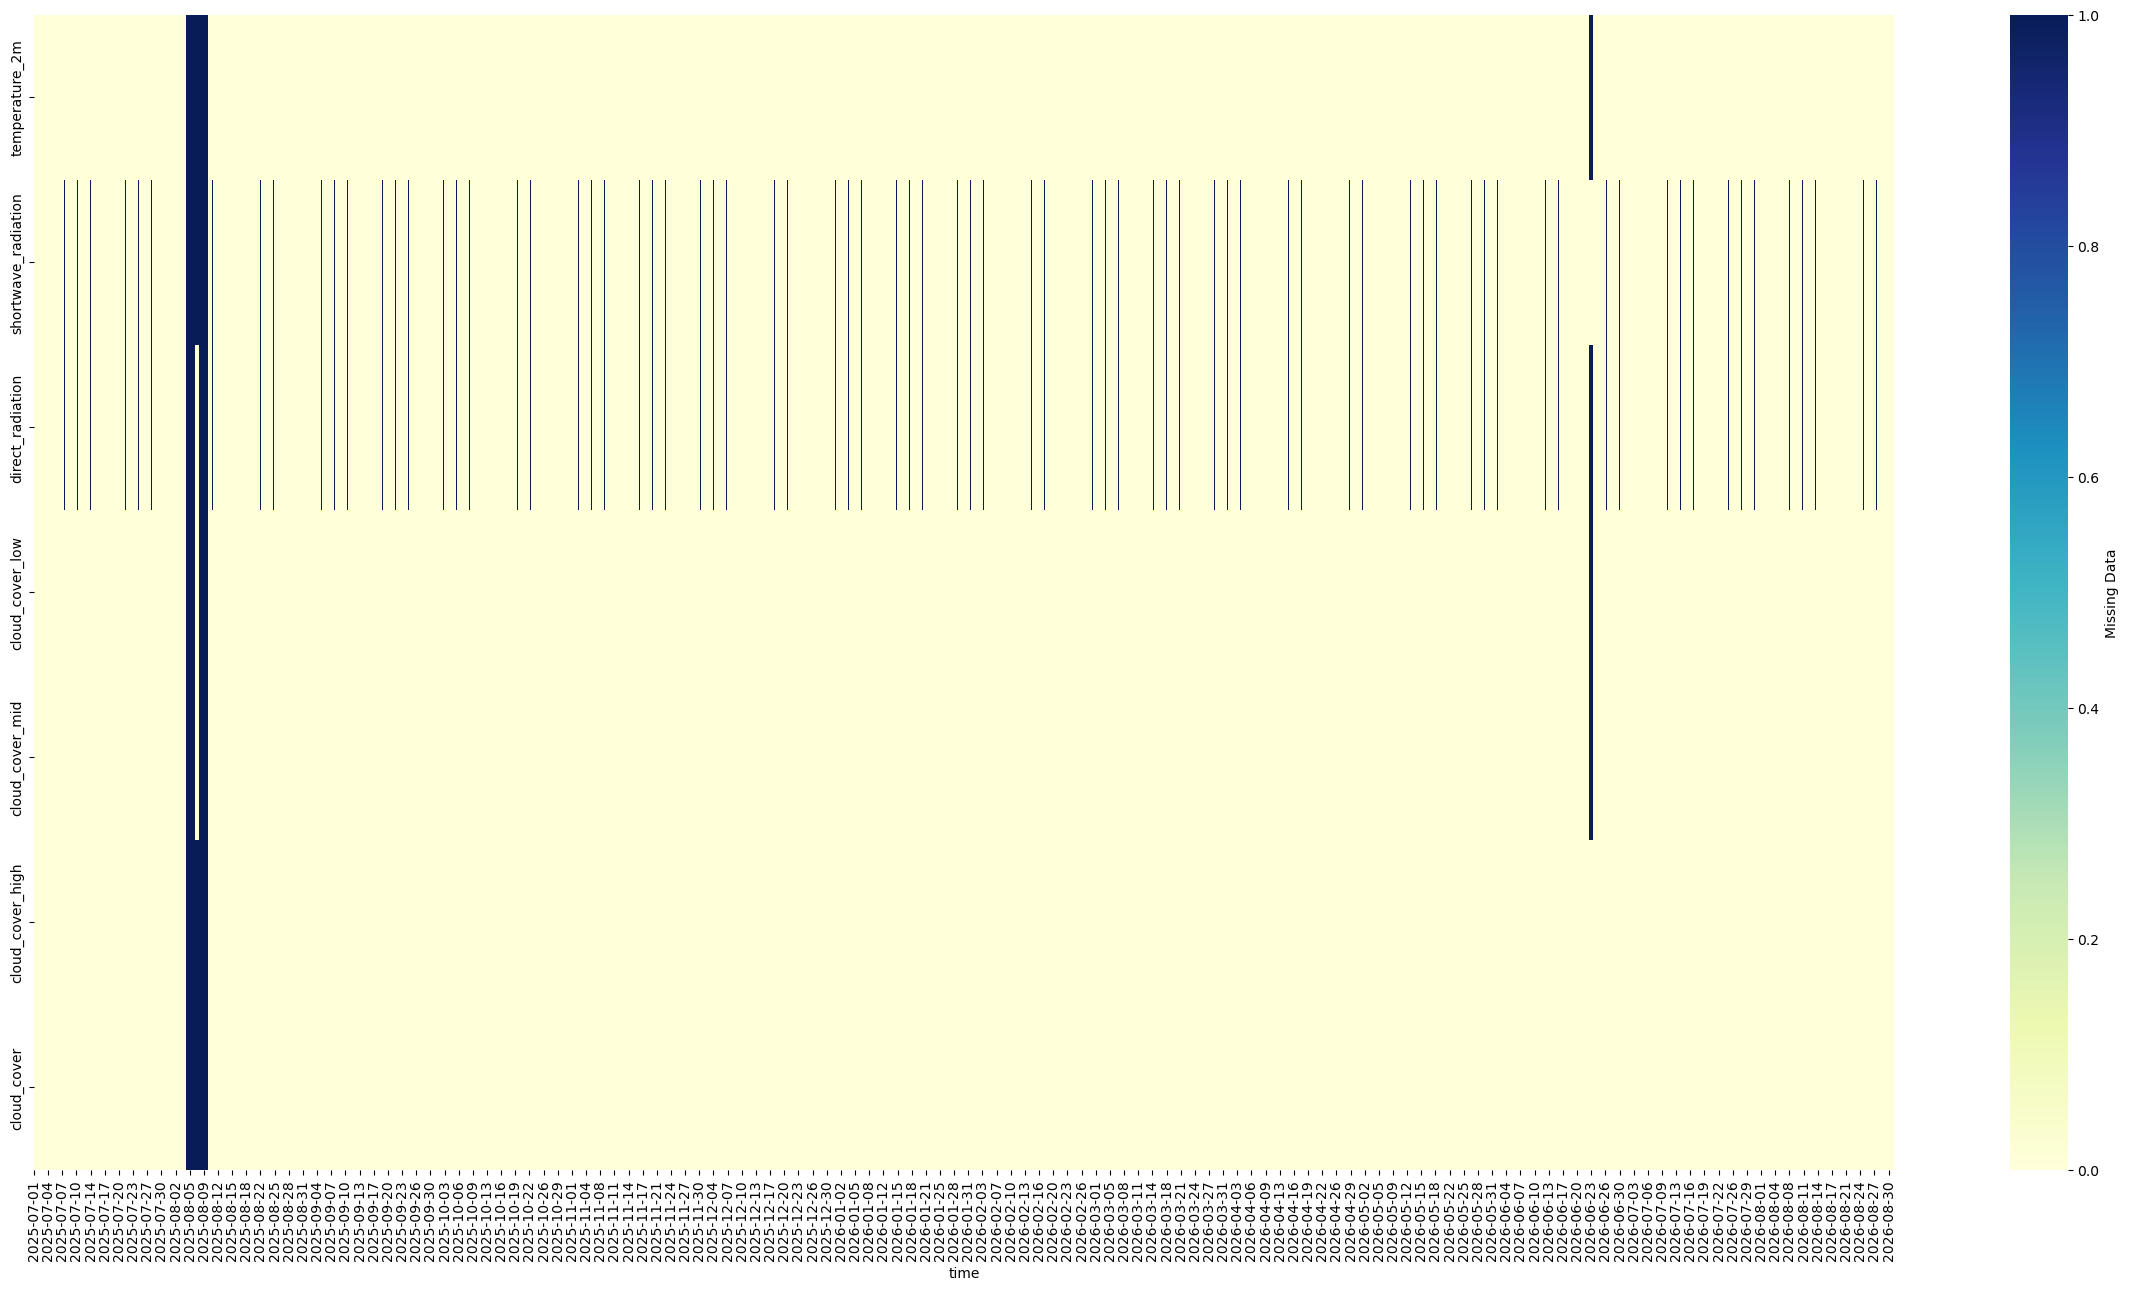

In [6]:
plot_missing_values(temp)

In [7]:
for c in CHANNELS:
    gaps = get_missing_value_gaps(temp[c]).sort_values("length_h", ascending=False)
    print(c + "\n")
    print("Number of gaps:", len(gaps))
    print(f"\nLongest gap:",gaps.head(1))
    print("\n")

    dist = gaps["length_h"].value_counts().sort_index()
    print(dist)
    print("\n")

temperature_2m

Number of gaps: 2

Longest gap:        start                 end  length_h
0 2025-08-05 2025-08-09 23:00:00       120


length_h
24     1
120    1
Name: count, dtype: int64


shortwave_radiation

Number of gaps: 422

Longest gap:         start        end  length_h
35 2025-08-05 2025-08-10       121


length_h
1      421
121      1
Name: count, dtype: int64


direct_radiation

Number of gaps: 422

Longest gap:         start        end  length_h
36 2025-08-08 2025-08-10        49


length_h
1     419
25      1
49      2
Name: count, dtype: int64


cloud_cover_low

Number of gaps: 3

Longest gap:        start                 end  length_h
0 2025-08-05 2025-08-06 23:00:00        48


length_h
24    1
48    2
Name: count, dtype: int64


cloud_cover_mid

Number of gaps: 3

Longest gap:        start                 end  length_h
0 2025-08-05 2025-08-06 23:00:00        48


length_h
24    1
48    2
Name: count, dtype: int64


cloud_cover_high

Number of gaps: 1

Longest gap:   

### Solar Power

In [ ]:
# Force hour periodicity 
temp = pv.copy()
temp = temp.set_index(['time']).sort_index()
full_idx = pd.date_range(START_DATE, END_DATE, freq="h", name="time")
temp = temp.reindex(full_idx)

print(f"Summary missing data:", temp.isna().sum(), temp.isna().mean() * 100)

In [ ]:
plot_missing_values(temp)

In [ ]:
gaps = get_missing_value_gaps(temp["solar_power"]).sort_values("length_h", ascending=False)
print("Solar Power\n")
print("Number of gaps:", len(gaps))
print(f"\nLongest gap:",gaps.head(1))
print("\n")

dist = gaps["length_h"].value_counts().sort_index()
print(dist)
print("\n")

## NWP Grid Variation

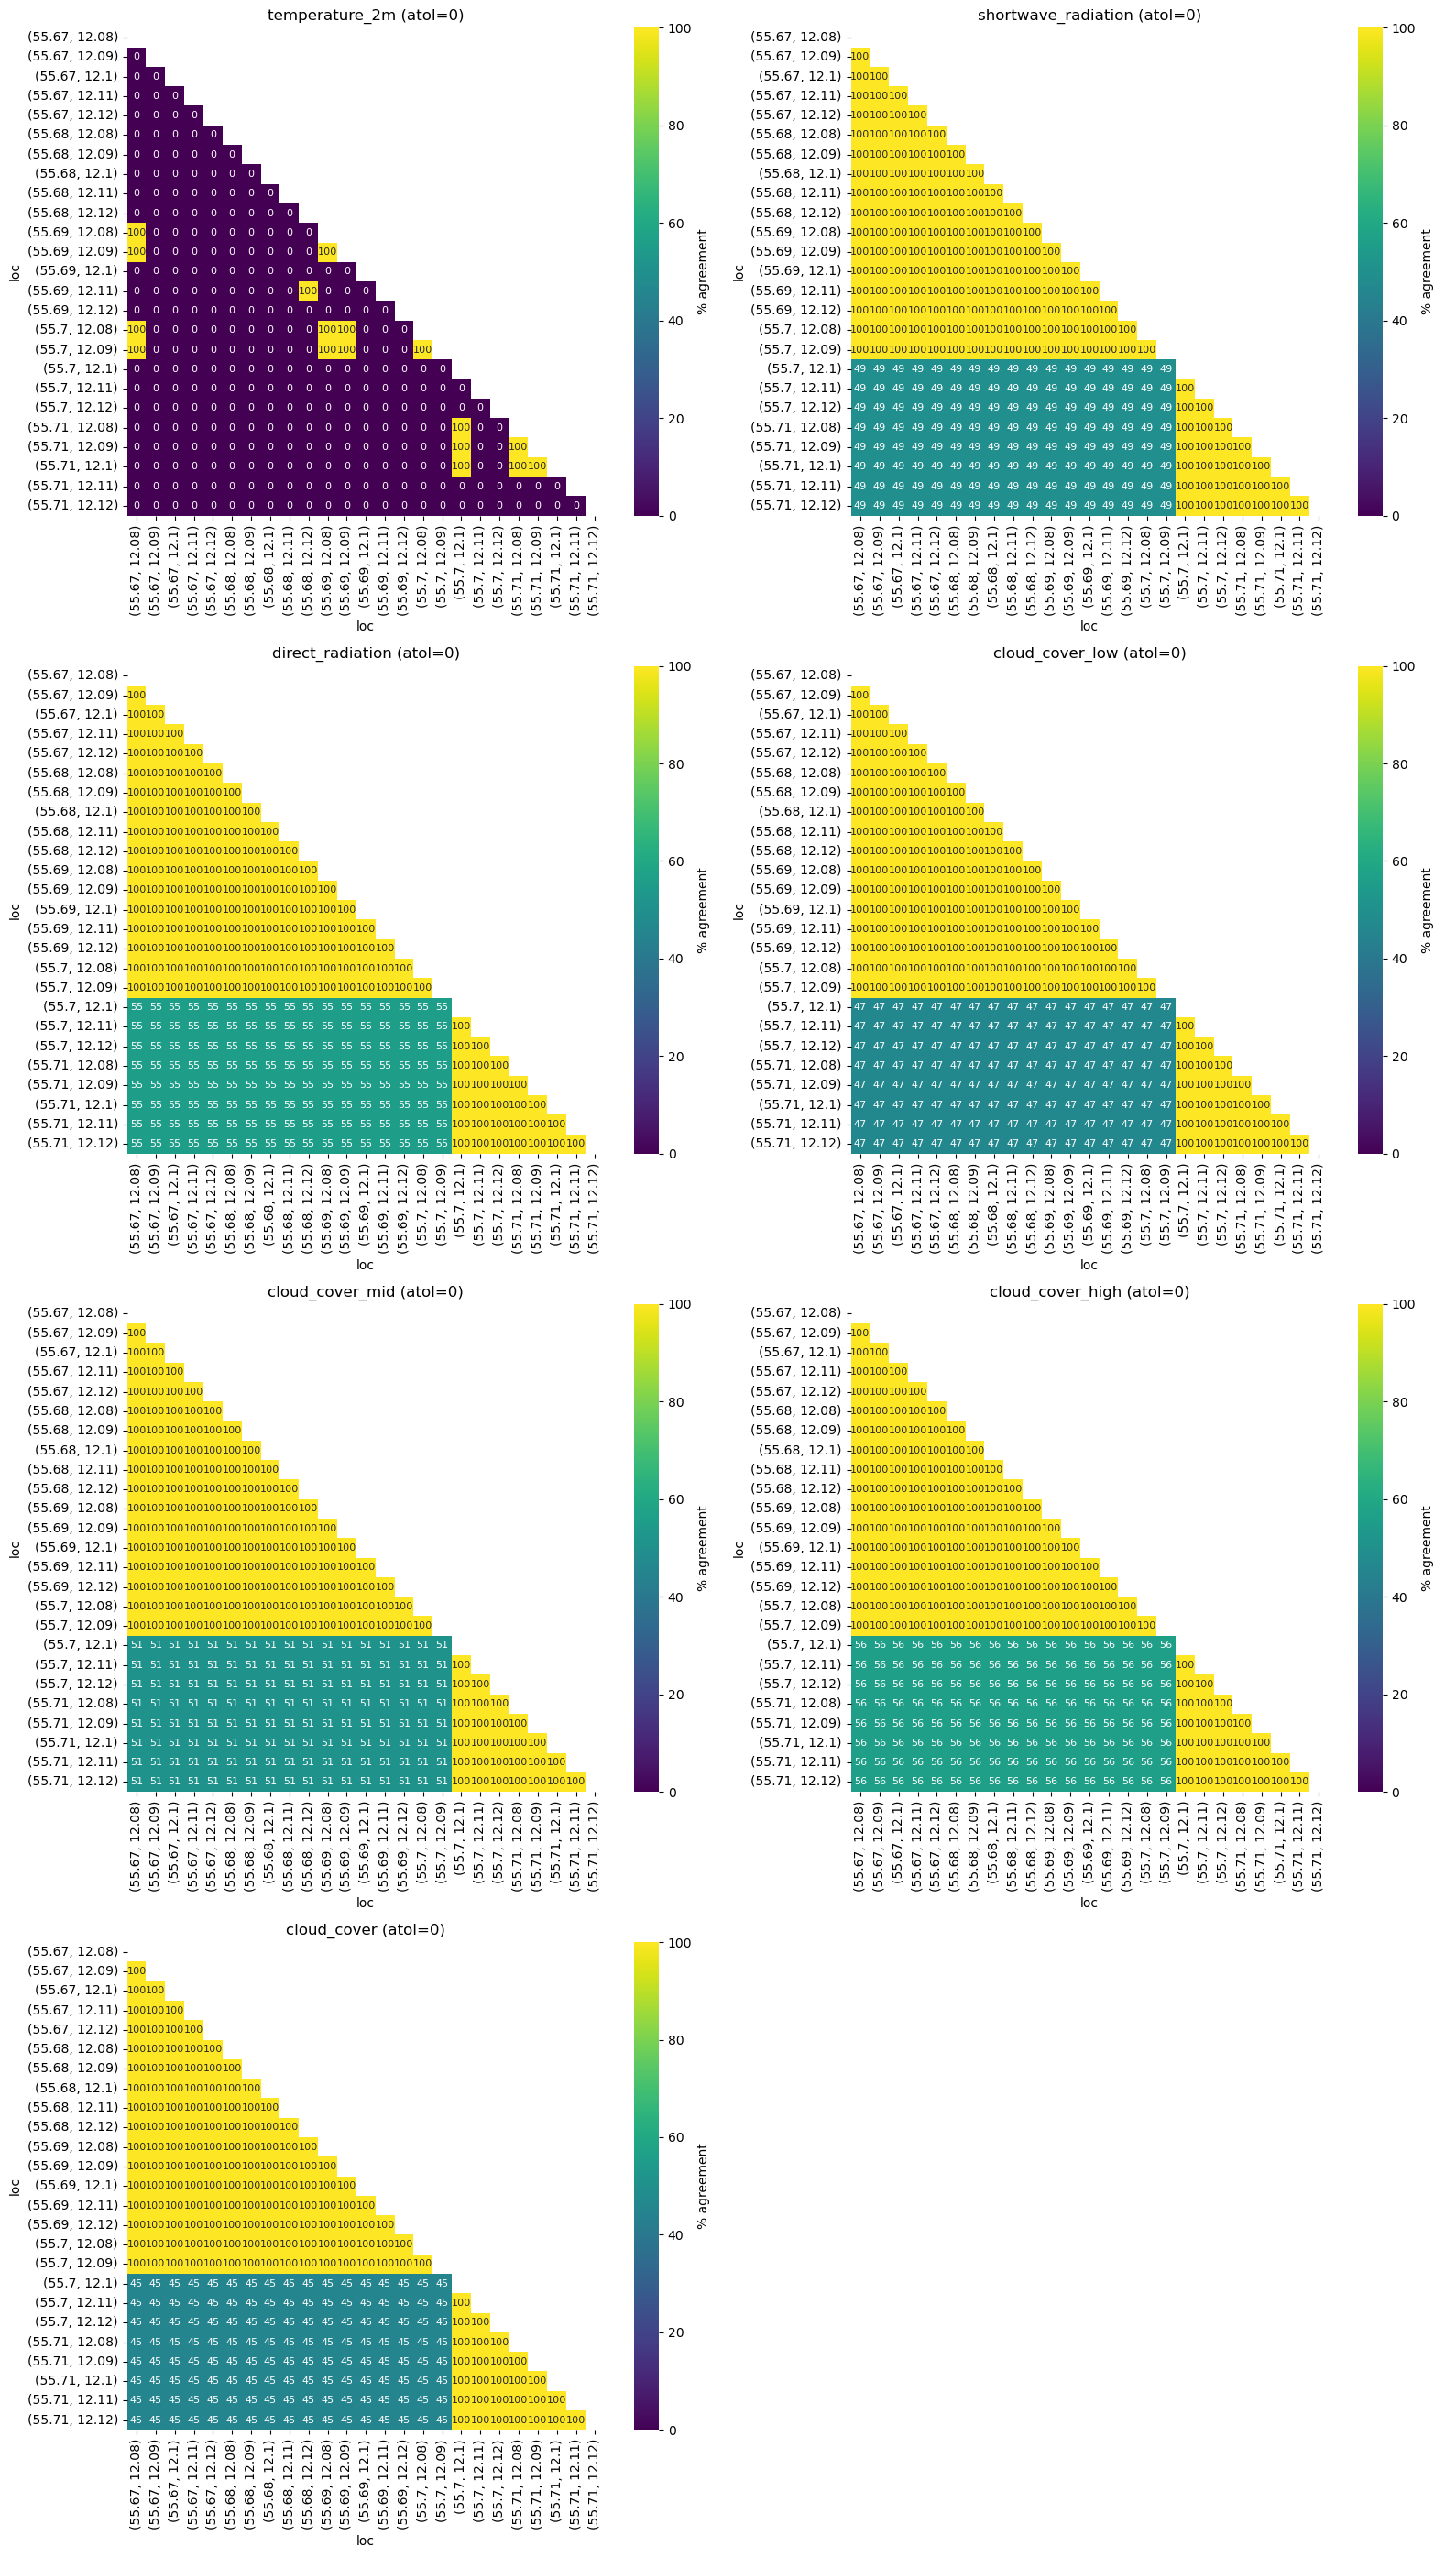

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

temp = nwp.copy()
temp["loc"] = list(zip(temp["latitude"], temp["longitude"]))

atol = {v: 0 for v in CHANNELS}

def to_wide(df, var):
    return df.pivot_table(index="time", columns="loc", values=var, aggfunc="first")

def change_summary(wide):
    d = wide.diff()
    return pd.DataFrame({
        "pct_hours_changed": (d.abs() > 0).sum() / d.notna().sum() * 100,
        "n_unique_values": wide.nunique(),
        "std": wide.std(),
        "mean_abs_hourly_change": d.abs().mean(),
    })

def agreement_matrix(wide, atol=0.0):
    cols = wide.columns
    arr = wide.to_numpy()
    out = np.full((len(cols), len(cols)), np.nan)
    for i in range(len(cols)):
        for j in range(i, len(cols)):
            valid = ~np.isnan(arr[:, i]) & ~np.isnan(arr[:, j])
            if valid.any():
                same = np.abs(arr[valid, i] - arr[valid, j]) <= atol
                out[i, j] = out[j, i] = same.mean() * 100
    return pd.DataFrame(out, index=cols, columns=cols)

def top_pairs(agree):
    agree = agree.rename_axis(index="loc_a", columns="loc_b")
    mask = np.triu(np.ones(agree.shape), k=1).astype(bool)
    p = agree.where(mask).stack().rename("pct_agree").reset_index()
    return p.sort_values("pct_agree", ascending=False)

results = {}

for var in CHANNELS:
    wide = to_wide(temp, var)
    agree = agreement_matrix(wide, atol=atol[var])
    results[var] = {
        "wide": wide,
        "change": change_summary(wide),
        "agree": agree,
        "pairs": top_pairs(agree),
    }

n = len(CHANNELS)
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 7 * nrows), squeeze=False)

for ax, var in zip(axes.ravel(), CHANNELS):
    mask = np.triu(np.ones_like(results[var]["agree"], dtype=bool))
    sns.heatmap(results[var]["agree"], cmap="viridis", vmin=0, vmax=100,
                cbar_kws={"label": "% agreement"}, annot=True, annot_kws={"fontsize":8}, fmt='.0f', mask=mask, ax=ax)
    ax.set_title(f"{var} (atol={atol[var]})")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
print(results[var]["change"].round(3))
print(results[var]["pairs"].head(10))   # most similar pairs
print(results[var]["pairs"].tail(10))   # least similar pairs

/home/sara/ITU/Thesis/ITU-Roof-Solar-Pannels-Data/DataAnalysis/claude_map.py:114: RuntimeWarning: Mean of empty slice
  mean, std = np.nanmean(vals), np.nanstd(vals)
/home/sara/anaconda3/envs/ResearchProject/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/sara/ITU/Thesis/ITU-Roof-Solar-Pannels-Data/DataAnalysis/claude_map.py:114: RuntimeWarning: Mean of empty slice
  mean, std = np.nanmean(vals), np.nanstd(vals)
/home/sara/anaconda3/envs/ResearchProject/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


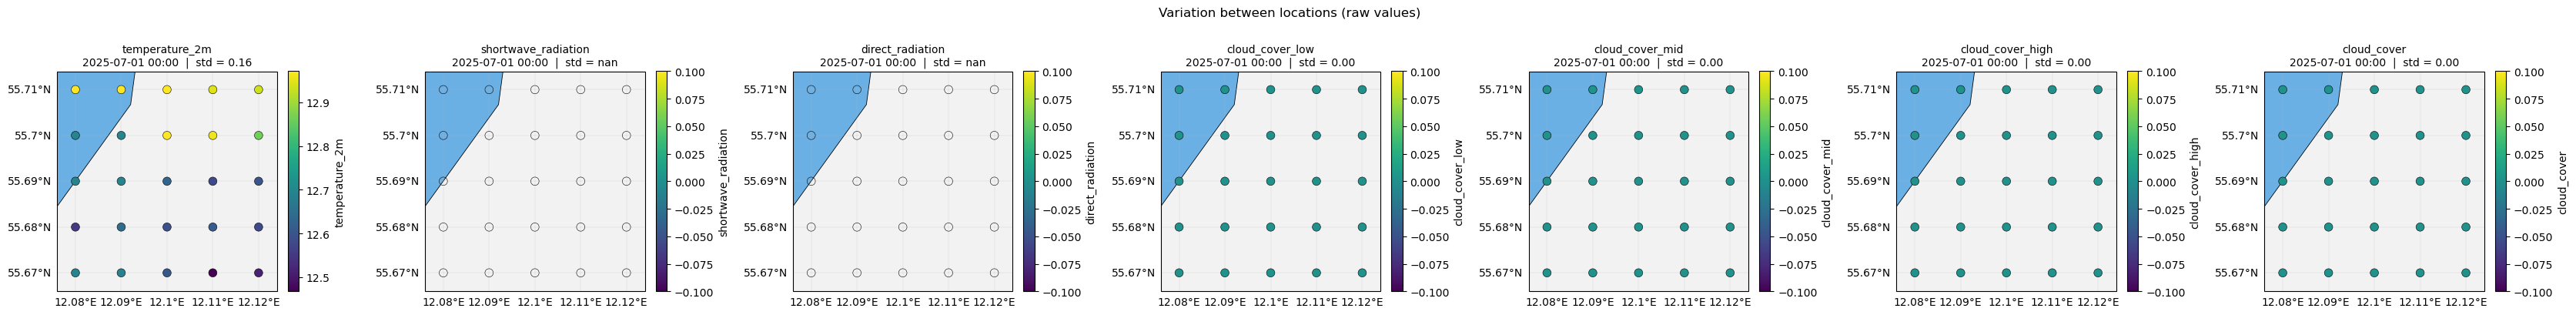

In [2]:
fig = plot_weather_map(
    nwp,
    times=["2025-11-01 17:00"],
    variables=CHANNELS,
    mode="value",                               
)

## How does Solar Power vary with NWP variables?

In [13]:
df = pd.merge(pv, nwp, how="outer")
temp = df.copy()
# Focusing on one coordinate pair for simplicity
latitude = temp['latitude'] == 55.67
longitude = temp['longitude'] == 12.08
temp = temp.loc[latitude & longitude]
temp = temp.drop(columns=["latitude", "longitude"])


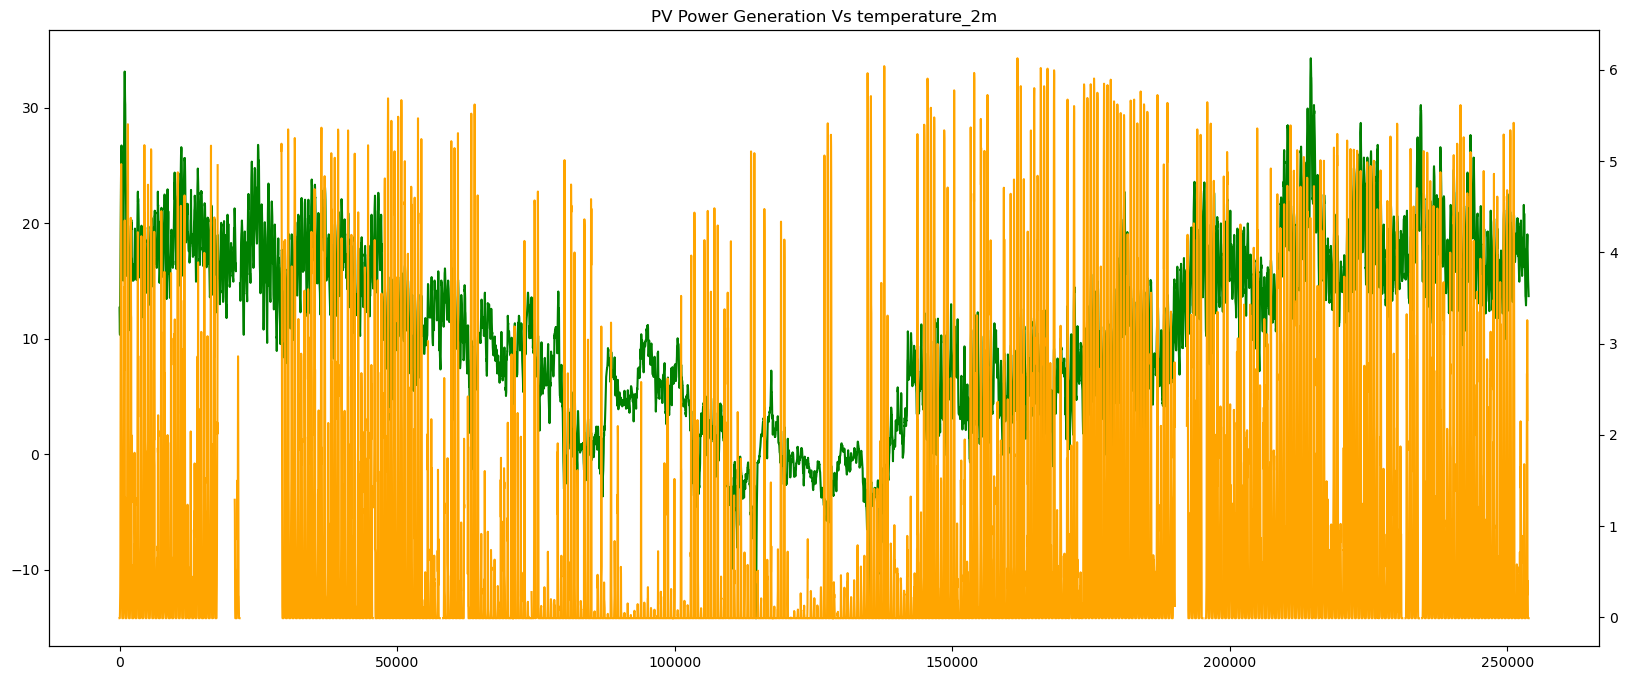

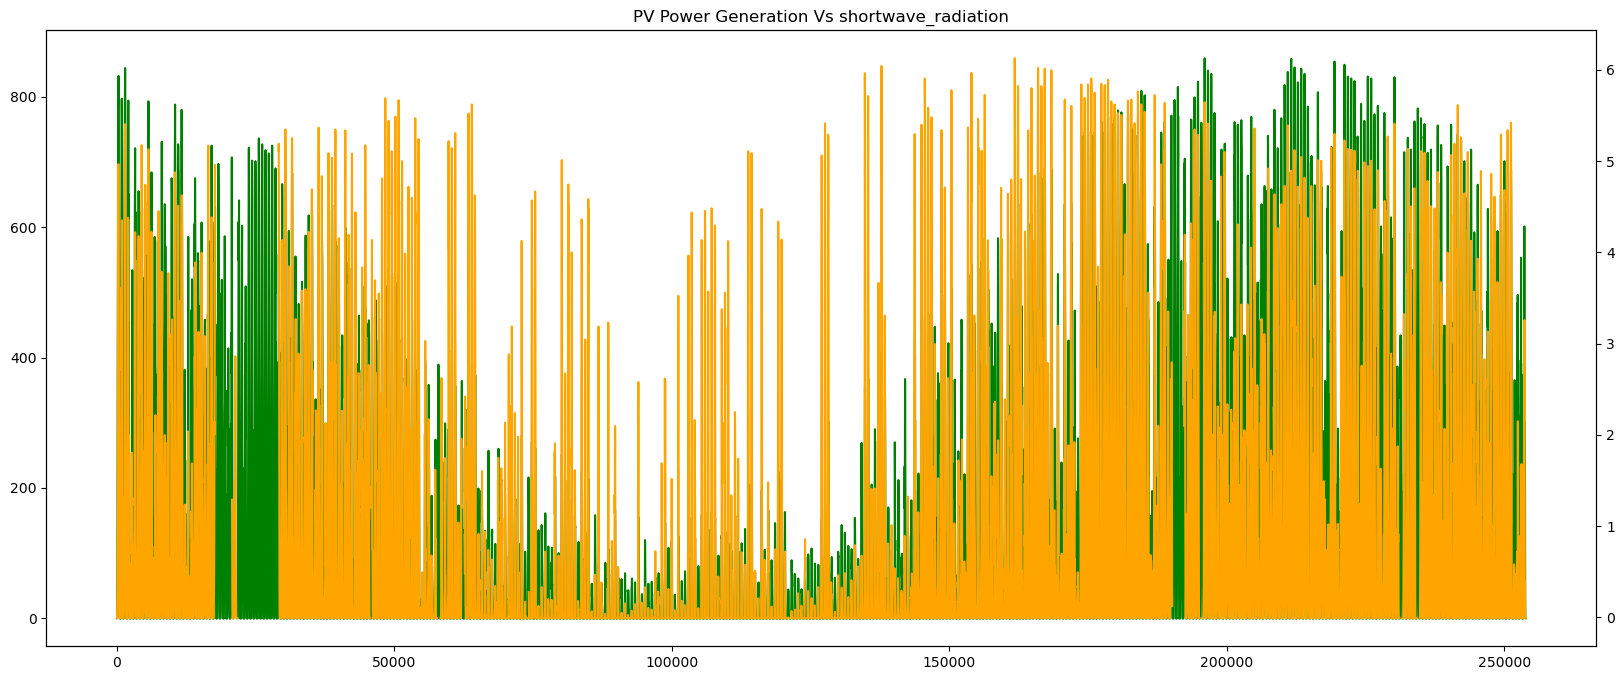

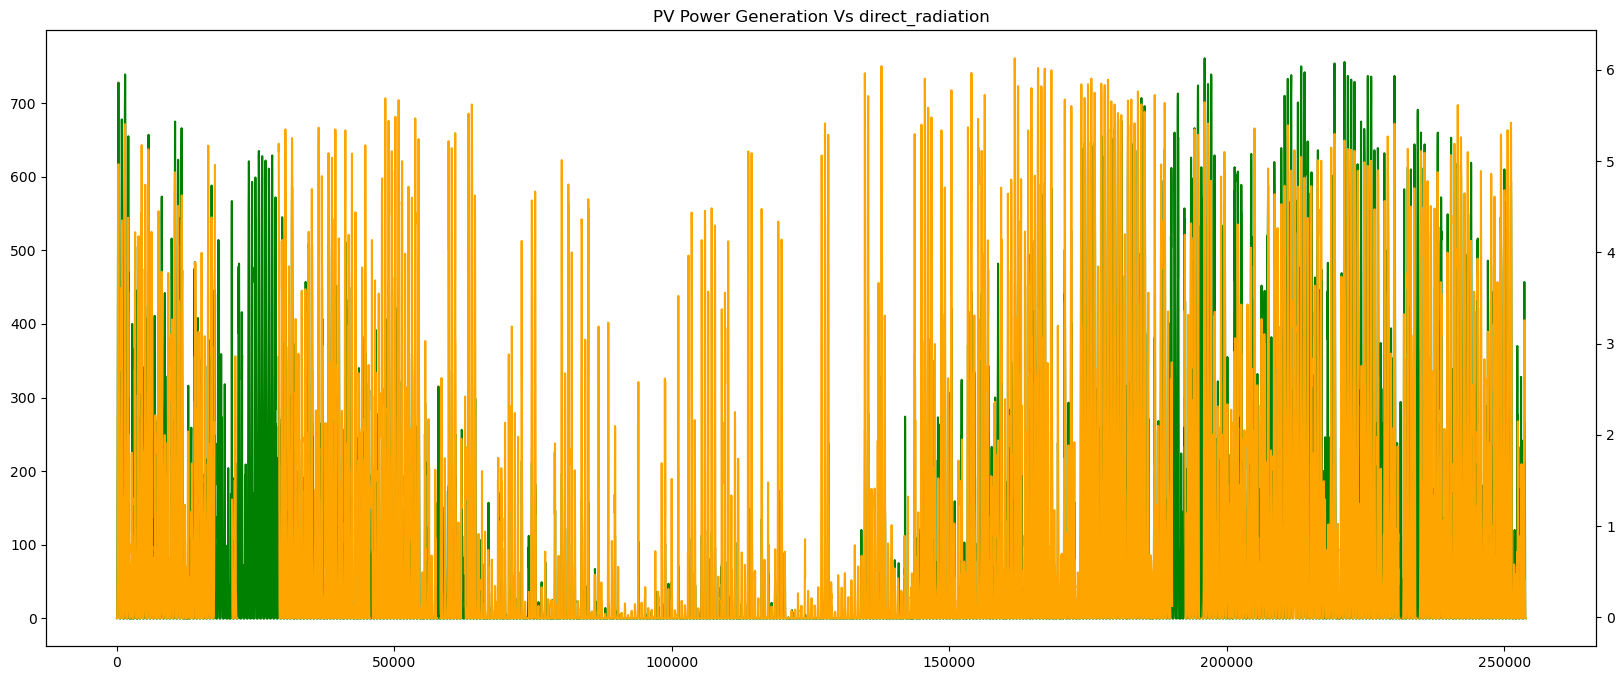

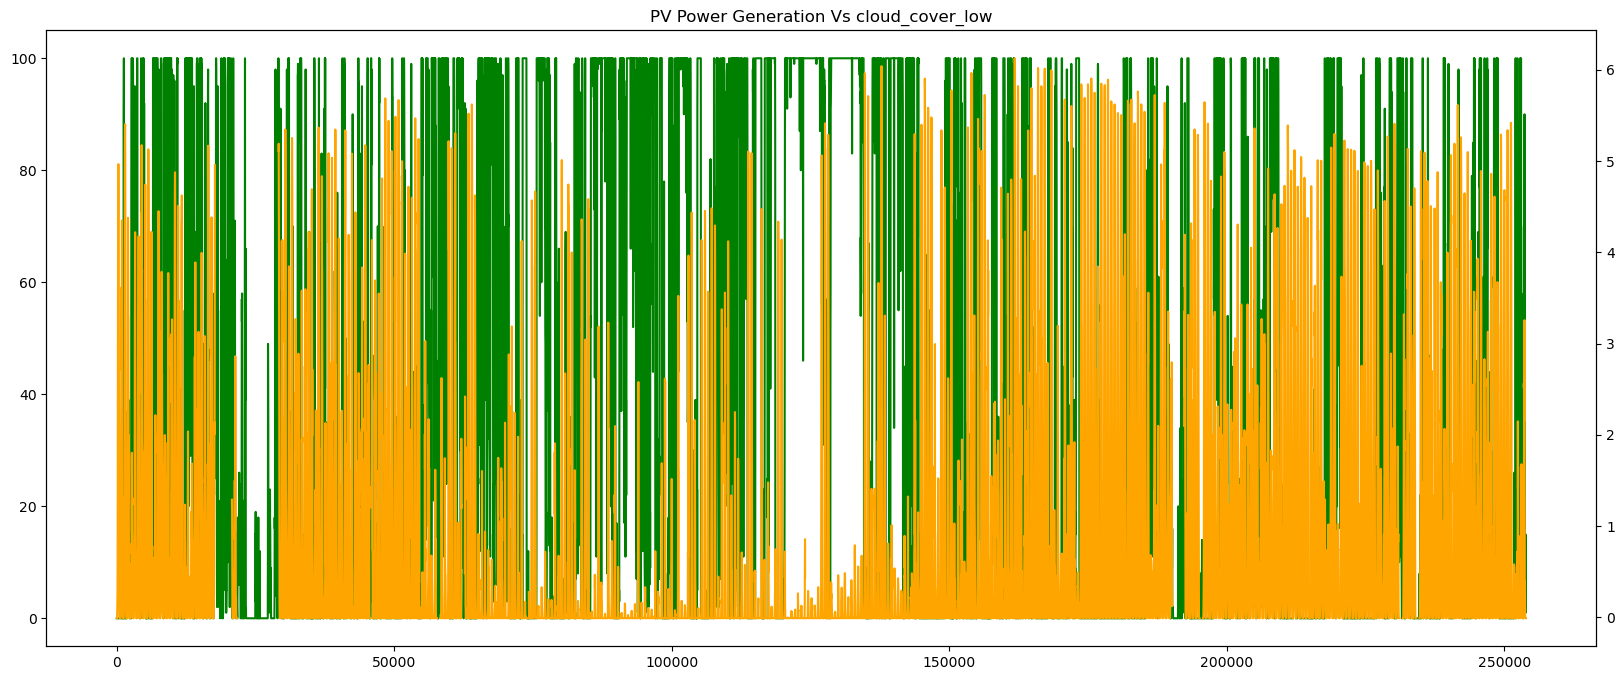

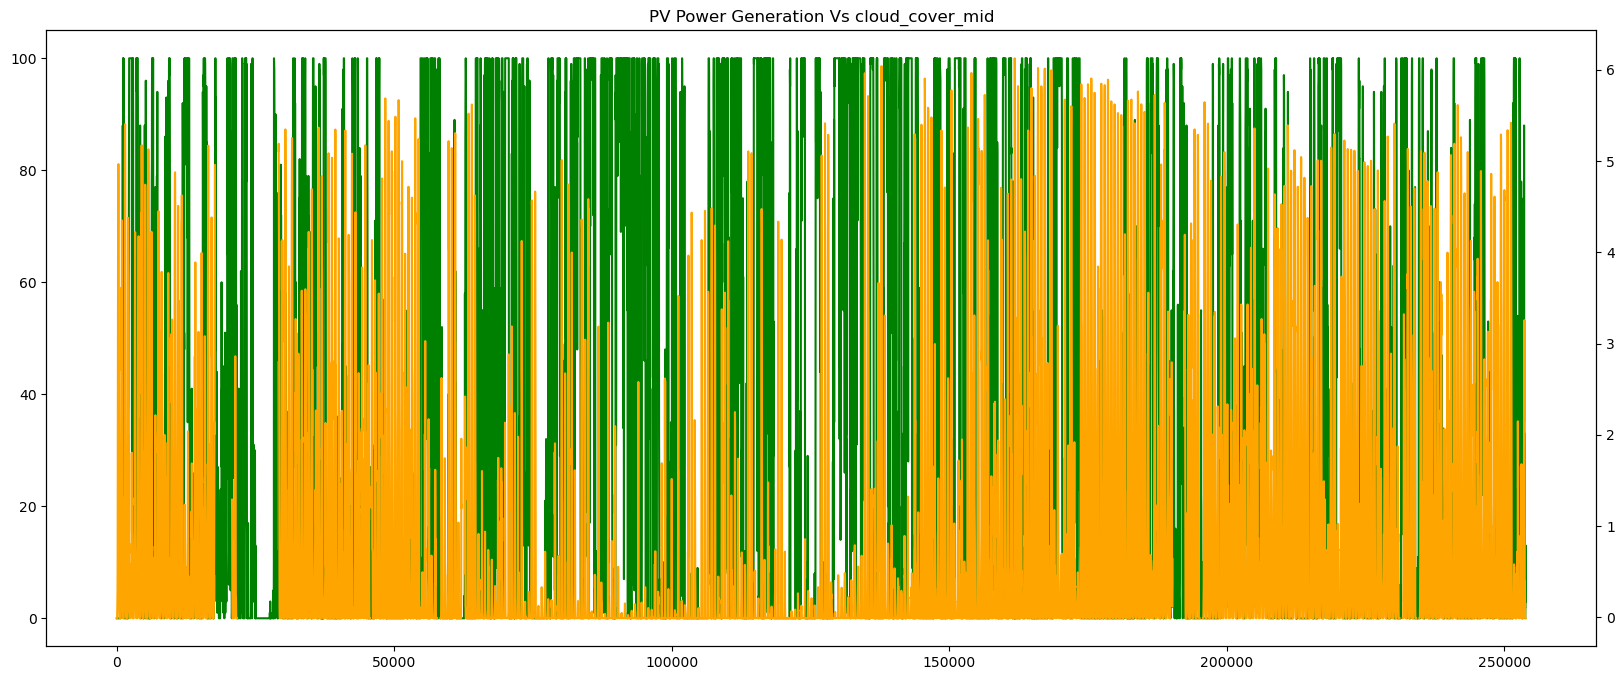

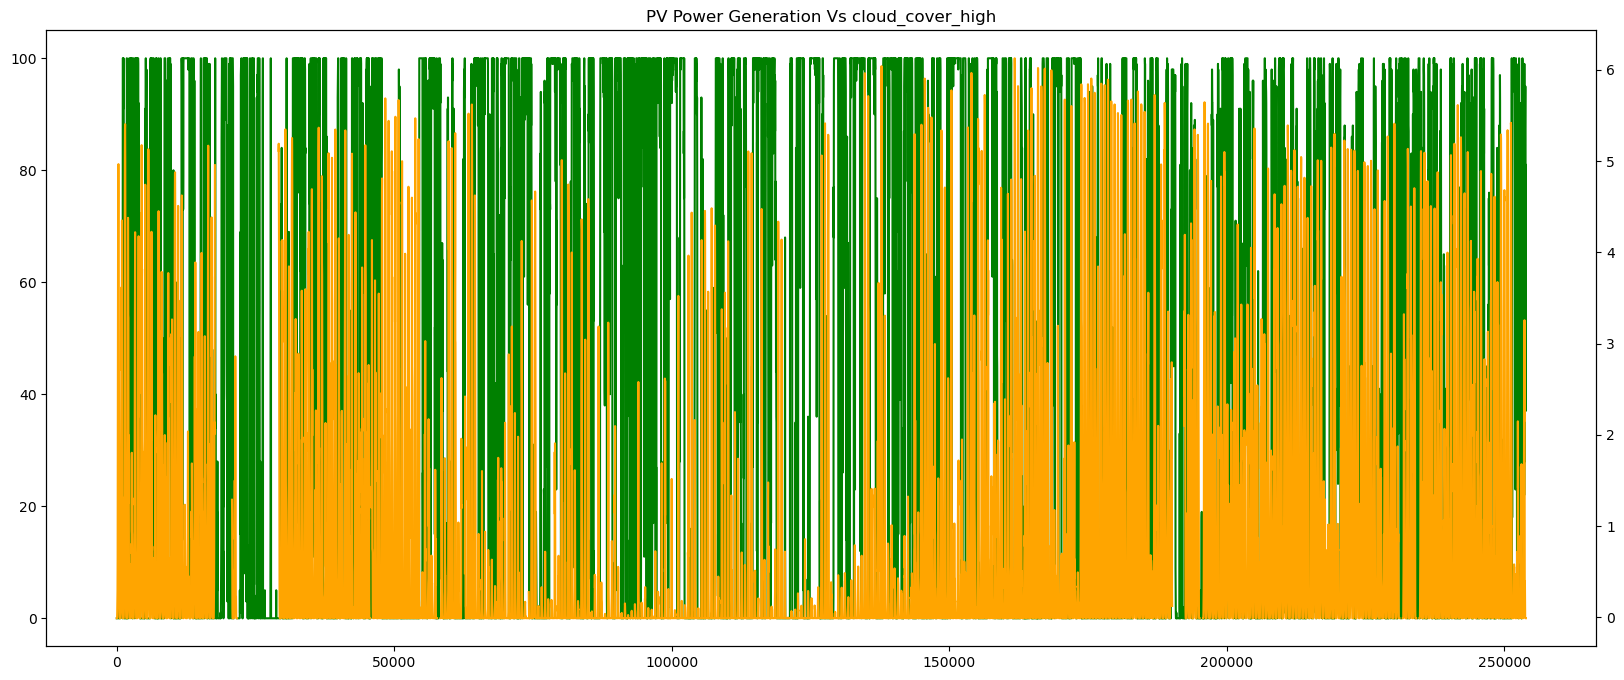

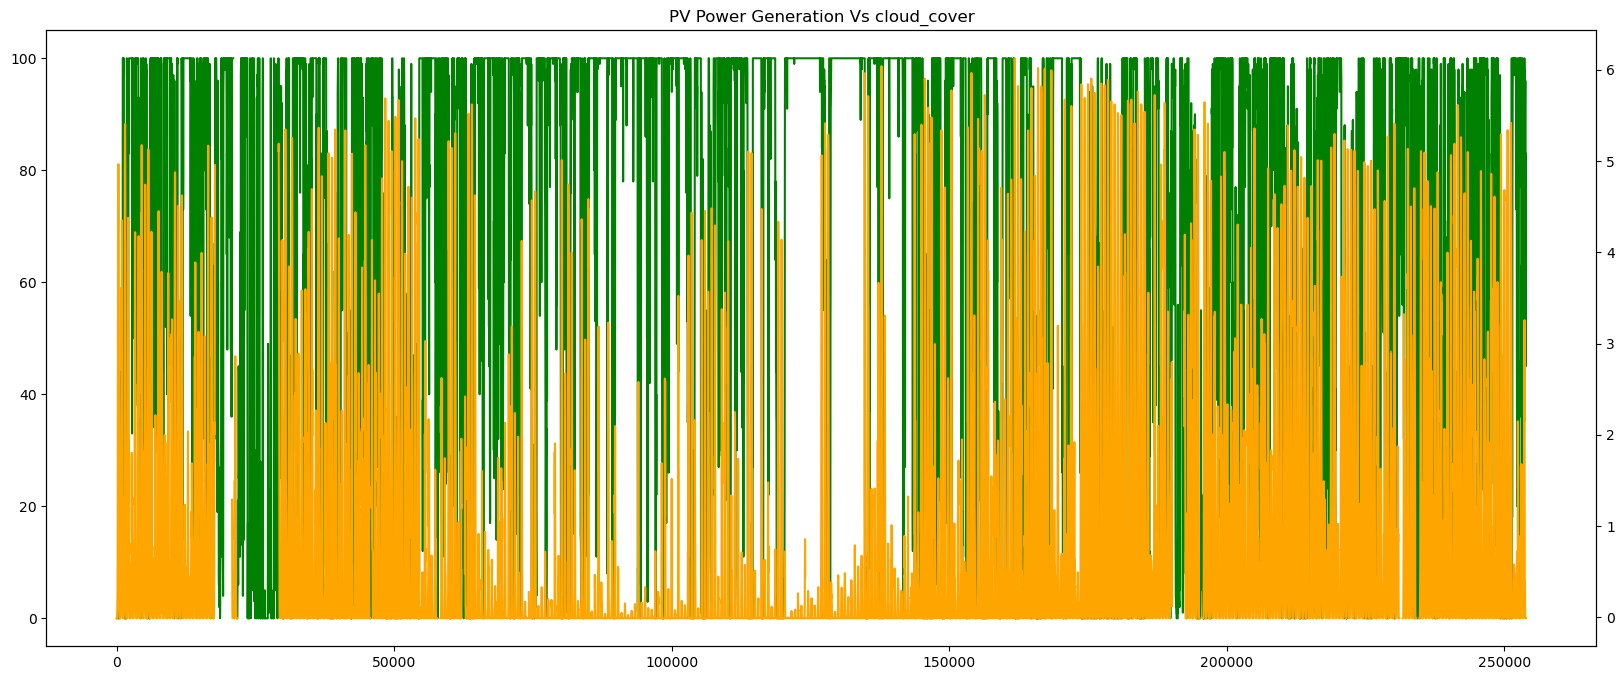

In [14]:
for c in CHANNELS:
    plot_nwp_vs_pv_data(temp, c)

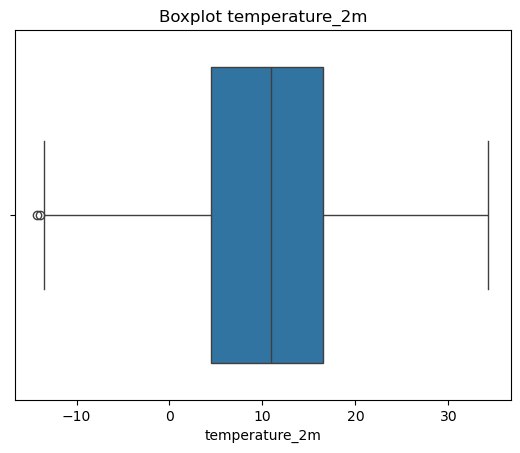

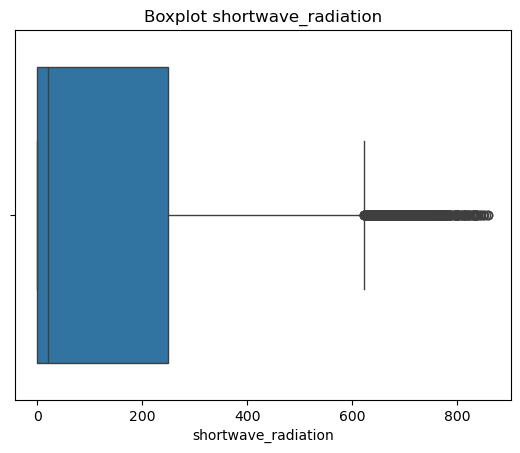

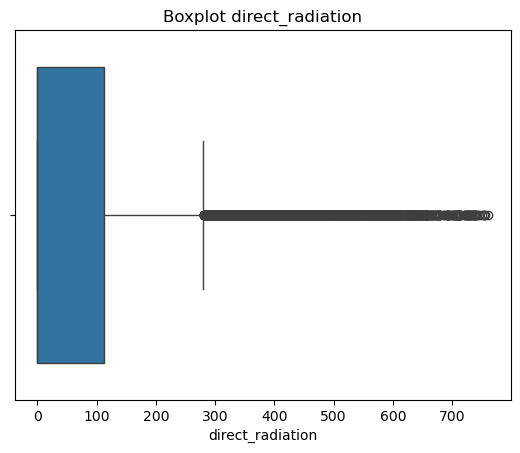

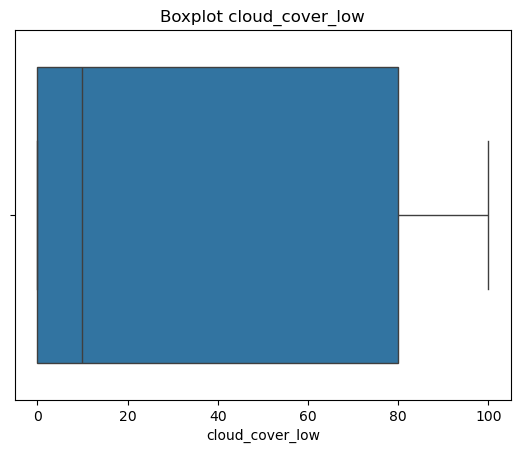

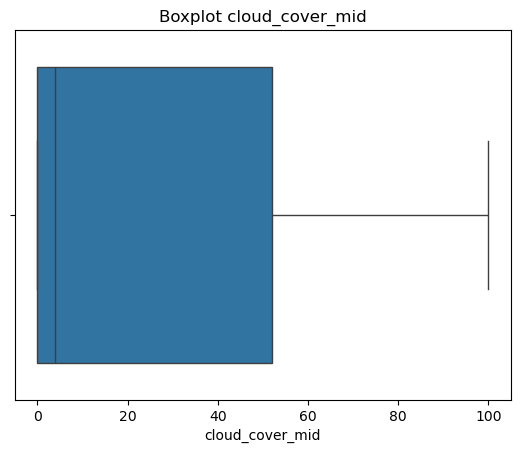

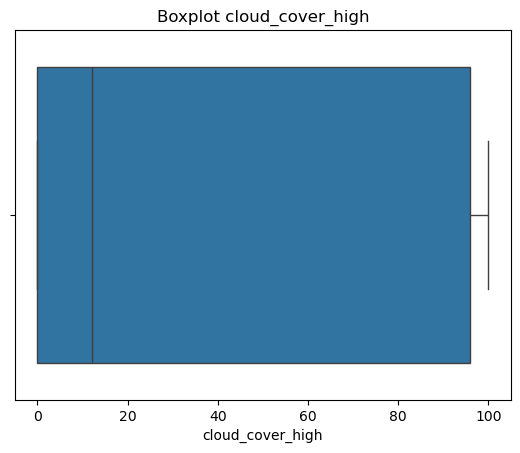

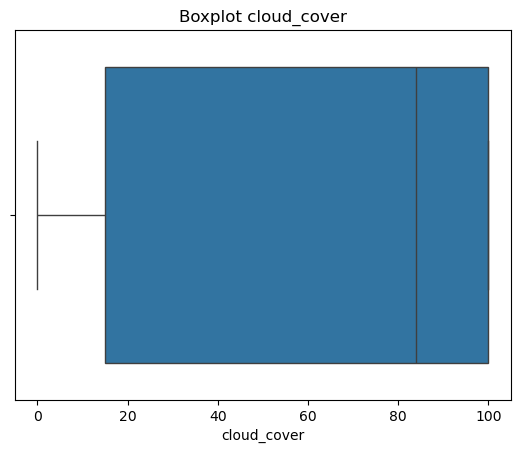

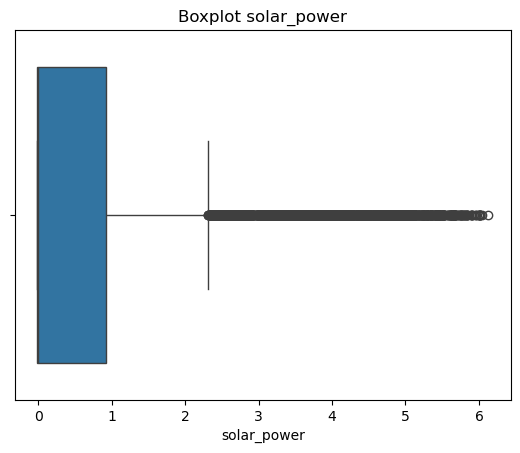

In [15]:
for c in CHANNELS:
    box_plot(temp, c)

box_plot(temp, 'solar_power')

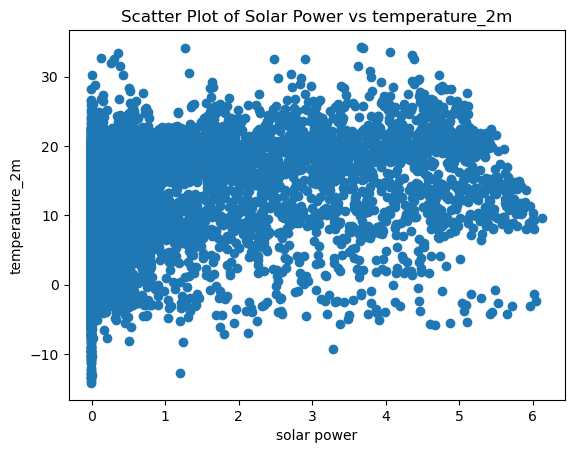

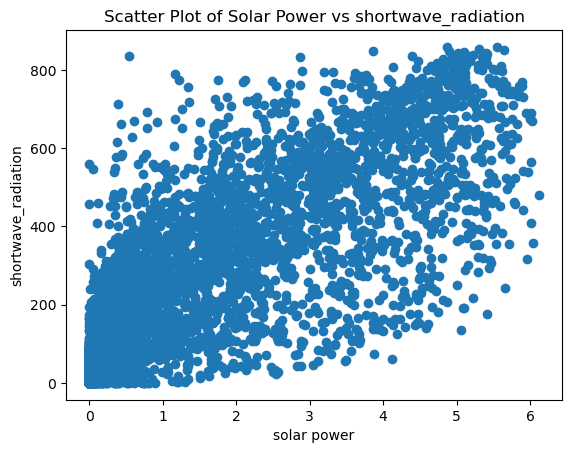

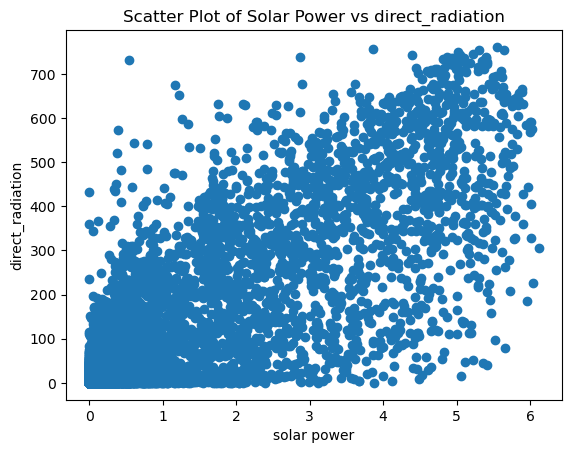

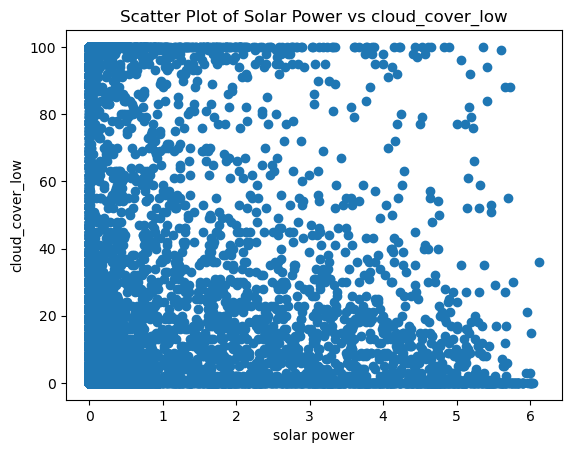

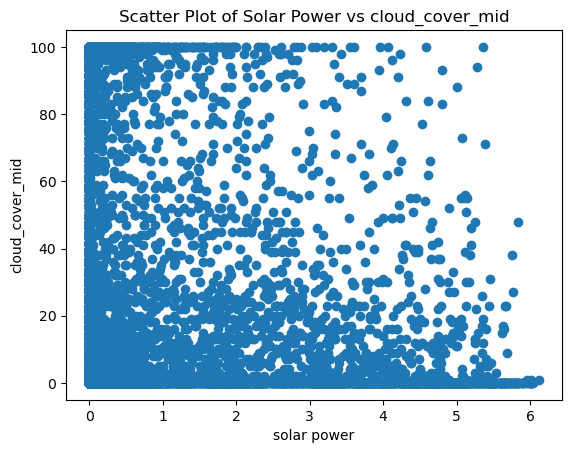

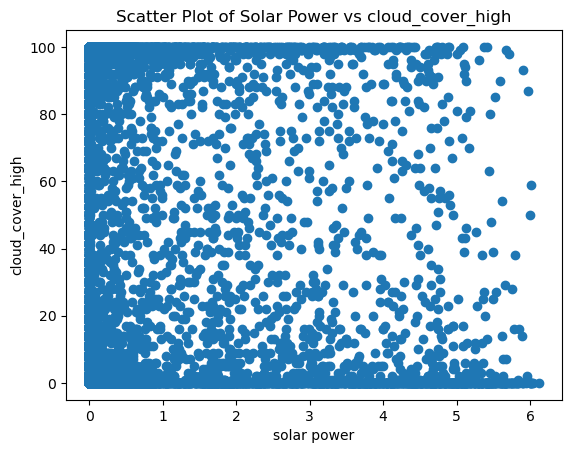

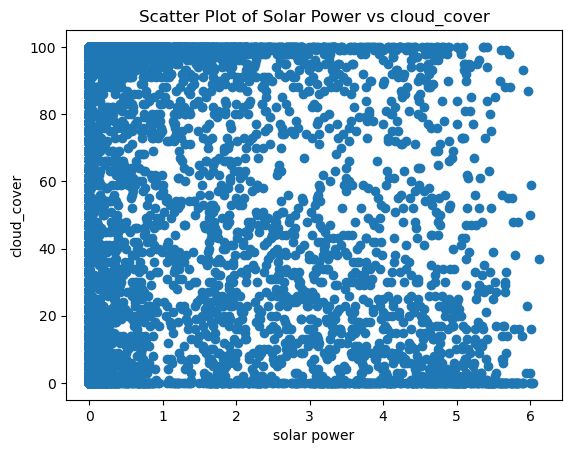

In [16]:
for c in CHANNELS:
    scatter_plot(temp, c)

In [17]:
for c in CHANNELS:
    z_score(df, c)

z_score(df, 'solar_power')

temperature_2mIndetified Outliers: 0
shortwave_radiationIndetified Outliers: 0
direct_radiationIndetified Outliers: 0
cloud_cover_lowIndetified Outliers: 0
cloud_cover_midIndetified Outliers: 0
cloud_cover_highIndetified Outliers: 0
cloud_coverIndetified Outliers: 0
solar_powerIndetified Outliers: 0
